# Classification d'images de chats et de chiens avec des CNN

## Objectif

Construire puis évaluer un réseau de neurones convolutionnel capable de classer une image en **chat (`0`)** ou **chien (`1`)**. Le projet suit deux étapes :

1. construire un CNN à quatre blocs afin de comprendre les convolutions, le pooling et le calcul des paramètres ;
2. chercher une meilleure performance avec des expériences contrôlées puis avec le transfert d'apprentissage.

**Résultat final évalué sur le test : 94,3 % d'accuracy et 94,2 % de F1-score.**

Ce notebook est la synthèse finale. Les sorties détaillées de chaque entraînement restent disponibles dans [`experiences_completes.ipynb`](experiences_completes.ipynb).

## 1. Protocole expérimental

Nous modifions **un facteur à la fois** et nous comparons les modèles sur le même jeu de validation.

- **Entraînement :** 1 600 images issues du dossier `train` de la prof.
- **Validation :** 1 000 images fournies dans le dossier `validation`.
- **Test final :** 400 images retirées du dossier `train` avant tout entraînement.
- **Séparation stratifiée :** chaque partie contient autant de chats que de chiens.
- **Graine aléatoire :** `42` pour rendre les comparaisons plus reproductibles.

Le test reste fermé pendant le choix du modèle. Il est ouvert une seule fois après la sélection du MobileNetV2 gelé.

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

CURRENT_DIR = Path.cwd()
PROJECT_DIR = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "notebooks"
    else CURRENT_DIR
)
DATA_DIR = PROJECT_DIR / "data"
TRAIN_DIR = DATA_DIR / "train"
VALIDATION_DIR = DATA_DIR / "validation"
MODELS_DIR = PROJECT_DIR / "models"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"

BATCH_SIZE = 100
LEARNING_RATE = 0.001

## 2. Données et séparation

Les chemins des fichiers constituent les entrées du pipeline. Le nom du dossier parent fournit le label : `cats → 0`, `dogs → 1`. `stratify` conserve les proportions des deux classes dans la séparation 80/20.

In [2]:
def path_to_label(path):
    return 0 if path.parent.name == "cats" else 1


all_train_files = sorted(TRAIN_DIR.glob("*/*.jpg"))
all_train_classes = [path.parent.name for path in all_train_files]

train_files, test_files = train_test_split(
    all_train_files,
    test_size=0.20,
    random_state=42,
    stratify=all_train_classes,
)
validation_files = sorted(VALIDATION_DIR.glob("*/*.jpg"))

train_labels = [path_to_label(path) for path in train_files]
validation_labels = [path_to_label(path) for path in validation_files]
test_labels = [path_to_label(path) for path in test_files]

print("Entraînement :", len(train_files), "images")
print("Validation    :", len(validation_files), "images")
print("Test final   :", len(test_files), "images")
print("Chats/chiens dans le test :", test_labels.count(0), "/", test_labels.count(1))

Entraînement : 1600 images
Validation    : 1000 images
Test final   : 400 images
Chats/chiens dans le test : 200 / 200


### Pourquoi trois jeux ?

- Le modèle apprend avec les données d'**entraînement**.
- La **validation** sert à comparer les réglages et à repérer le surapprentissage.
- Le **test** estime la généralisation une fois les décisions terminées.

Utiliser le test pour choisir les réglages provoquerait une fuite d'information : il ne mesurerait plus honnêtement la performance sur des données inconnues.

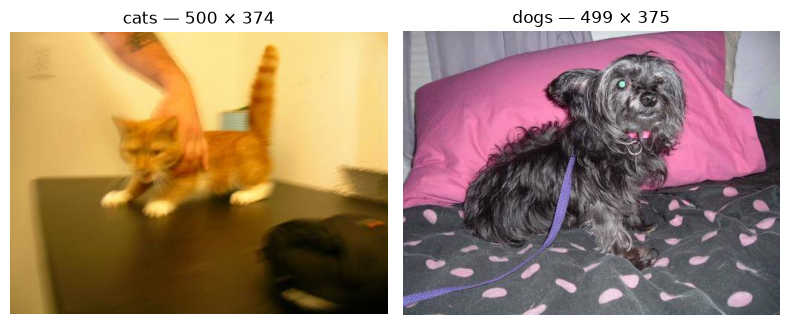

In [3]:
from PIL import Image

sample_paths = [
    next((TRAIN_DIR / "cats").glob("*.jpg")),
    next((TRAIN_DIR / "dogs").glob("*.jpg")),
]

figure, axes = plt.subplots(1, 2, figsize=(8, 4))
for axis, path in zip(axes, sample_paths):
    image = Image.open(path)
    axis.imshow(image)
    axis.set_title(f"{path.parent.name} — {image.size[0]} × {image.size[1]}")
    axis.axis("off")
plt.tight_layout()
plt.show()

## 3. Prétraitement

Les images ont des dimensions différentes. `resize_with_pad` les redimensionne vers un carré sans déformer l'animal et complète les bords si nécessaire. Les valeurs RGB passent ensuite de `[0, 255]` à `[0, 1]`.

Le mélange est appliqué uniquement à l'entraînement. La validation et le test gardent un ordre stable.

In [4]:
def prepare_image_and_label(image_path, label, target_size):
    image_bytes = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image_bytes, channels=3)
    image = tf.image.resize_with_pad(image, target_size, target_size)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label


def make_dataset(files, labels, target_size, batch_size=100, should_shuffle=False):
    path_strings = [str(path) for path in files]
    dataset = tf.data.Dataset.from_tensor_slices((path_strings, labels))

    if should_shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(files),
            seed=42,
        )

    dataset = dataset.map(
        lambda path, label: prepare_image_and_label(path, label, target_size),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    return dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

## 4. CNN construit à la main

Chaque bloc applique :

1. une convolution `3 × 3` qui produit des cartes de caractéristiques ;
2. ReLU, qui remplace les scores négatifs par zéro ;
3. un MaxPooling `2 × 2`, qui divise la hauteur et la largeur par deux.

Le nombre de filtres augmente (`16 → 32 → 64 → 128`) pendant que les dimensions spatiales diminuent. `GlobalAveragePooling2D` résume chaque carte finale par sa moyenne, puis une couche dense décide entre chat et chien.

In [5]:
def build_cnn(input_size):
    inputs = keras.Input(shape=(input_size, input_size, 3))
    x = inputs

    for block_number, number_of_filters in enumerate([16, 32, 64, 128], start=1):
        x = layers.Conv2D(
            filters=number_of_filters,
            kernel_size=(3, 3),
            padding="same",
            activation="relu",
            name=f"convolution_{block_number}",
        )(x)
        x = layers.MaxPooling2D(
            pool_size=(2, 2),
            name=f"pooling_{block_number}",
        )(x)

    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dense(64, activation="relu", name="dense_features")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="prediction")(x)
    return keras.Model(inputs, outputs, name="cnn_chats_chiens")


keras.utils.set_random_seed(42)
custom_cnn = build_cnn(128)
custom_cnn.summary()

Model: "cnn_chats_chiens"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ convolution_1 (Conv2D)          │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_1 (MaxPooling2D)        │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ convolution_2 (Conv2D)          │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_2 (MaxPooling2D)        │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ convolution_3 (Conv2D)          │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_3 (MaxPooling2D)        │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ convolution_4 (Conv2D)          │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_4 (MaxPooling2D)        │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,761 (413.13 KB)

 Trainable params: 105,761 (413.13 KB)

 Non-trainable params: 0 (0.00 B)

### Calcul des paramètres

Un filtre de convolution contient :

$$k_h \times k_w \times C_{entrée} + 1\text{ biais}$$

Ce nombre est multiplié par le nombre de filtres. Par exemple, la première couche reçoit trois canaux RGB :

$$ (3 \times 3 \times 3 + 1) \times 16 = 448 $$

| Couche | Calcul | Paramètres |
|---|---:|---:|
| Conv 1 | `(3×3×3 + 1) × 16` | 448 |
| Conv 2 | `(3×3×16 + 1) × 32` | 4 640 |
| Conv 3 | `(3×3×32 + 1) × 64` | 18 496 |
| Conv 4 | `(3×3×64 + 1) × 128` | 73 856 |
| Dense 64 | `(128 + 1) × 64` | 8 256 |
| Sigmoïde | `(64 + 1) × 1` | 65 |
| **Total** |  | **105 761** |

ReLU, MaxPooling et GlobalAveragePooling n'ont aucun poids entraînable.

## 5. Baseline

La baseline utilise des images `128 × 128`, Adam avec un learning rate de `0.001`, la binary cross-entropy, des batches de 100 et 10 epochs.

In [6]:
baseline_size = 128
baseline_train_dataset = make_dataset(
    train_files, train_labels, baseline_size, BATCH_SIZE, should_shuffle=True
)
baseline_validation_dataset = make_dataset(
    validation_files, validation_labels, baseline_size, BATCH_SIZE
)

custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
)

# Entraînement exécuté dans le notebook d'exploration :
# baseline_history = custom_cnn.fit(
#     baseline_train_dataset,
#     validation_data=baseline_validation_dataset,
#     epochs=10,
#     verbose=2,
# )

![Courbes de la baseline](../artifacts/baseline_training_curves.png)

La baseline atteint **65,3 % d'accuracy de validation** avec une loss minimale proche de **0,620**. Les courbes d'entraînement et de validation restent relativement proches : le problème principal est un apprentissage encore limité, plutôt qu'un fort surapprentissage.

## 6. Recherches et expériences contrôlées

Nous conservons les expériences utiles, y compris celles qui échouent. Une méthode plausible n'est retenue que si les résultats de validation la soutiennent.

### 6.1 Durée d'entraînement

Porter le maximum de 10 à 15 epochs améliore légèrement le CNN : **66,5 %** d'accuracy et **0,596** de loss. Le gain de 1,2 point reste faible par rapport au calcul supplémentaire. Augmenter encore les epochs n'est donc pas notre priorité.

### 6.2 Résolution du CNN personnalisé

Toutes les autres conditions restent identiques pendant ce test.

In [7]:
custom_resolution_results = {
    "96 × 96":  {"accuracy": 0.655, "loss": 0.609, "seconds": 36.1},
    "128 × 128": {"accuracy": 0.653, "loss": 0.620, "seconds": 55.0},
    "160 × 160": {"accuracy": 0.640, "loss": 0.619, "seconds": 90.2},
}

print("Résolution | val_accuracy | val_loss | temps")
for name, result in custom_resolution_results.items():
    print(
        f"{name:>9} | {result['accuracy']:.3f}        | "
        f"{result['loss']:.3f}    | {result['seconds']:.1f} s"
    )

Résolution | val_accuracy | val_loss | temps
  96 × 96 | 0.655        | 0.609    | 36.1 s
128 × 128 | 0.653        | 0.620    | 55.0 s
160 × 160 | 0.640        | 0.619    | 90.2 s


![Comparaison des résolutions du CNN](../artifacts/resolution_comparison.png)

`96 × 96` traite 44 % de pixels en moins que `128 × 128`, s'entraîne environ 34 % plus vite et ne perd pas d'accuracy. Nous le retenons pour les expériences suivantes du CNN personnalisé. L'écart de 0,2 point est trop petit pour prétendre que `96 × 96` est intrinsèquement plus précis.

### 6.3 Augmentation des données

L'augmentation est appliquée uniquement pendant l'entraînement. Elle présente plusieurs versions réalistes d'une même image afin que le modèle apprenne des caractéristiques stables.

In [8]:
strong_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal", seed=42),
        layers.RandomRotation(0.05, seed=43),
        layers.RandomZoom(0.10, seed=44),
        layers.RandomContrast(0.10, seed=45),
    ],
    name="strong_augmentation",
)

light_augmentation = keras.Sequential(
    [layers.RandomFlip("horizontal", seed=42)],
    name="light_augmentation",
)

![Exemples d'augmentation](../artifacts/augmentation_examples.png)

| Configuration | Meilleure validation | Loss minimale | Décision |
|---|---:|---:|---|
| Sans augmentation | **65,5 %** | **0,609** | Retenue pour le CNN |
| Flip + rotation + zoom + contraste | 58,9 % | 0,659 | Trop difficile en 10 epochs |
| Flip horizontal seulement | 65,0 % | 0,623 | Proche, mais aucun gain |

![Comparaison des augmentations](../artifacts/light_augmentation_comparison.png)

L'augmentation forte ralentit l'apprentissage sur ce petit modèle. Le flip seul récupère la performance, mais ne dépasse pas la baseline. Nous ne retenons donc aucune augmentation pour le modèle sélectionné.

### 6.4 Batch Normalization et Dropout

Batch Normalization stabilise les distributions intermédiaires. Dropout masque aléatoirement une partie des activations pendant l'entraînement pour limiter la dépendance à quelques neurones.

In [9]:
def build_batchnorm_dropout_cnn(input_size):
    inputs = keras.Input(shape=(input_size, input_size, 3))
    x = inputs

    for block_number, number_of_filters in enumerate([16, 32, 64, 128], start=1):
        x = layers.Conv2D(
            number_of_filters,
            (3, 3),
            padding="same",
            use_bias=False,
            name=f"convolution_{block_number}",
        )(x)
        x = layers.BatchNormalization(name=f"batch_norm_{block_number}")(x)
        x = layers.Activation("relu", name=f"relu_{block_number}")(x)
        x = layers.MaxPooling2D((2, 2), name=f"pooling_{block_number}")(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.20, seed=42)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="cnn_batchnorm_dropout")

![Batch Normalization et Dropout](../artifacts/batchnorm_dropout_comparison.png)

Le modèle atteint **80,3 % sur l'entraînement**, mais seulement **50,4 % sur la validation**, avec une loss proche de `0,694`. Nous rejetons cette configuration.

Les statistiques mobiles de Batch Normalization sont une hypothèse possible pour expliquer la mauvaise validation dans ce court entraînement, mais nous ne la présentons pas comme une cause prouvée. Il faudrait tester séparément BatchNorm et Dropout pour établir la cause.

## 7. Transfert d'apprentissage avec MobileNetV2

Le CNN personnalisé apprend tous ses filtres à partir de seulement 1 600 images. MobileNetV2 possède déjà des filtres appris sur ImageNet. Nous gelons cette base et remplaçons son ancien classifieur par un seul neurone sigmoïde.

Après GlobalAveragePooling, le neurone final reçoit **1 280 valeurs** : il contient donc `1 280 poids + 1 biais = 1 281 paramètres entraînables`. Les 2 257 984 paramètres gelés participent toujours au calcul avant, mais ils ne sont pas modifiés.

In [10]:
def build_frozen_mobilenet(input_size):
    base = keras.applications.MobileNetV2(
        input_shape=(input_size, input_size, 3),
        include_top=False,
        weights="imagenet",
    )
    base.trainable = False

    inputs = keras.Input(shape=(input_size, input_size, 3))
    x = layers.Rescaling(2.0, offset=-1.0)(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="mobilenetv2_chats_chiens")


transfer_model = build_frozen_mobilenet(96)
trainable_parameters = sum(
    int(np.prod(weight.shape)) for weight in transfer_model.trainable_weights
)
frozen_parameters = sum(
    int(np.prod(weight.shape)) for weight in transfer_model.non_trainable_weights
)
print("Paramètres entraînables :", trainable_parameters)
print("Paramètres gelés        :", frozen_parameters)

Paramètres entraînables : 1281
Paramètres gelés        : 2257984


In [11]:
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
)

transfer_train_dataset = make_dataset(
    train_files, train_labels, 96, BATCH_SIZE, should_shuffle=True
)
transfer_validation_dataset = make_dataset(
    validation_files, validation_labels, 96, BATCH_SIZE
)

# Entraînement ayant produit le modèle sélectionné avant l'ouverture du test :
# transfer_history = transfer_model.fit(
#     transfer_train_dataset,
#     validation_data=transfer_validation_dataset,
#     epochs=5,
#     verbose=2,
# )
# transfer_model.save(MODELS_DIR / "mobilenetv2_frozen.keras")

![Apprentissage de MobileNetV2](../artifacts/mobilenetv2_training.png)

| Modèle | Validation | Loss | Temps |
|---|---:|---:|---:|
| CNN personnalisé `96 × 96` | 65,5 % | 0,609 | 36,1 s |
| MobileNetV2 gelé `96 × 96` | **93,9 %** | **0,138** | **32,4 s** |

MobileNetV2 est sélectionné avant l'ouverture du test : il apporte un gain de 28,4 points d'accuracy tout en entraînant seulement la nouvelle tête de classification.

## 8. Évaluation finale

Le modèle sélectionné est chargé depuis le fichier sauvegardé. Le seuil `0,5` transforme sa probabilité en classe. Ici, la classe positive est **chien (`1`)**.

In [12]:
final_model = keras.models.load_model(
    MODELS_DIR / "mobilenetv2_frozen.keras"
)
final_test_dataset = make_dataset(
    test_files, test_labels, 96, BATCH_SIZE
)

test_probabilities = final_model.predict(
    final_test_dataset,
    verbose=0,
).reshape(-1)
test_predictions = (test_probabilities >= 0.5).astype(int)
test_labels_array = np.asarray(test_labels)

test_accuracy = accuracy_score(test_labels_array, test_predictions)
test_precision = precision_score(test_labels_array, test_predictions)
test_recall = recall_score(test_labels_array, test_predictions)
test_f1 = f1_score(test_labels_array, test_predictions)
test_confusion = confusion_matrix(test_labels_array, test_predictions)

print(f"Accuracy  : {test_accuracy:.3f}")
print(f"Précision : {test_precision:.3f}")
print(f"Rappel    : {test_recall:.3f}")
print(f"F1-score  : {test_f1:.3f}")
print("Matrice de confusion :")
print(test_confusion)

Accuracy  : 0.943
Précision : 0.945
Rappel    : 0.940
F1-score  : 0.942
Matrice de confusion :
[[189  11]
 [ 12 188]]


![Matrice de confusion finale](../artifacts/final_confusion_matrix.png)

| Mesure | Résultat | Interprétation |
|---|---:|---|
| Accuracy | **94,3 %** | 377 images correctes sur 400 |
| Précision chien | **94,5 %** | Parmi les images prédites « chien », 94,5 % sont des chiens |
| Rappel chien | **94,0 %** | 94 % des vrais chiens sont retrouvés |
| F1-score | **94,2 %** | Équilibre entre précision et rappel |

La matrice `[[189, 11], [12, 188]]` signifie : 189 chats et 188 chiens correctement reconnus, 11 chats pris pour des chiens et 12 chiens pris pour des chats.

## 9. Recherches postérieures au test

Après l'évaluation finale, nous avons étudié l'arrêt anticipé, la résolution de MobileNetV2 et le fine-tuning. Ces essais restent intéressants pour comprendre le modèle, mais ils ne remplacent pas le score officiel de 94,3 %, car le test avait déjà été ouvert.

In [13]:
post_test_results = {
    "96 gelé — 15 epochs max": {
        "accuracy": 0.951, "loss": 0.118, "seconds": 133.8
    },
    "96 fine-tuné": {
        "accuracy": 0.956, "loss": 0.112, "seconds": 41.7
    },
    "128 gelé — 15 epochs max": {
        "accuracy": 0.966, "loss": 0.088, "seconds": 224.8
    },
    "128 fine-tuné": {
        "accuracy": 0.967, "loss": 0.084, "seconds": 40.1
    },
}

print("Configuration                  | val_accuracy | val_loss")
for name, result in post_test_results.items():
    print(f"{name:<30} | {result['accuracy']:.3f}        | {result['loss']:.3f}")

Configuration                  | val_accuracy | val_loss
96 gelé — 15 epochs max        | 0.951        | 0.118
96 fine-tuné                   | 0.956        | 0.112
128 gelé — 15 epochs max       | 0.966        | 0.088
128 fine-tuné                  | 0.967        | 0.084


![Comparaison MobileNetV2 96 et 128](../artifacts/mobilenetv2_resolution_comparison.png)

La résolution `128 × 128` produit le principal gain postérieur : **+1,5 point** par rapport au modèle gelé `96 × 96`, pour environ **68 % de temps supplémentaire**. Le fine-tuning des 20 dernières couches ajoute seulement **0,1 point** à `128 × 128`.

Cette faible amélioration, avec une accuracy d'entraînement proche de 100 %, indique des rendements décroissants et un risque croissant de mémorisation. Nous arrêtons donc la recherche d'hyperparamètres plutôt que d'adapter sans fin nos décisions à la validation.

## 10. Conclusion

Le CNN personnalisé permet de comprendre tout le parcours de l'image : convolution, cartes de caractéristiques, ReLU, pooling, moyenne globale et classification. Sur ce petit dataset, apprendre tous les filtres depuis zéro reste limité à environ 65–66 % de validation.

Le transfert d'apprentissage change fortement le résultat : les caractéristiques visuelles déjà apprises par MobileNetV2 permettent d'obtenir **94,3 % sur le test final**, avec des erreurs équilibrées entre chats et chiens.

### Décisions principales

- conserver le padding pour respecter les proportions des animaux ;
- utiliser `96 × 96` comme résolution efficace pour le CNN personnalisé ;
- rejeter les augmentations testées et BatchNorm + Dropout, car elles n'améliorent pas la validation ;
- sélectionner MobileNetV2 gelé avant l'ouverture du test ;
- conserver `128 × 128` et le fine-tuning comme recherches postérieures, sans transformer leurs scores de validation en scores de test.

### Limites

- dataset relativement petit ;
- une seule graine aléatoire, donc les petits écarts ne prouvent pas une amélioration générale ;
- certaines images peuvent être ambiguës ou contenir un arrière-plan trompeur ;
- plusieurs décisions successives sur la même validation peuvent finir par la suradapter indirectement.